# Xây dựng mô hình nhận diện chuỗi chữ số viết tay

## 1. Cấu hình

In [1]:
import sys
sys.path.append('..')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from keras.models import Model
from keras.layers import (
    Input, Conv2D, MaxPooling2D, Reshape, Dense, GRU, Embedding, Permute,
    Bidirectional, AdditiveAttention, BatchNormalization, Activation, Concatenate
)
from keras.optimizers import AdamW
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score

In [2]:
IMG_SHAPE = (28, 224, 1)
VOCAB_SIZE = 13
MAX_SEQ_LEN = 9

PAD_TOKEN = 10
START_TOKEN = 11
END_TOKEN = 12

VERSION = "v3"

## 2. Chuẩn bị dữ liệu

In [3]:
labels = pd.read_csv('../datasets/labels.csv')
labels = labels['label'].values

max_seq_len = max(len(str(label)) for label in labels)

print(f"Số lượng mẫu: {len(labels)}")
print(f"Chiều dài tối đa của chuỗi: {max_seq_len}")
print(f"Mẫu ví dụ đầu tiên: {labels[0]}")

Số lượng mẫu: 60000
Chiều dài tối đa của chuỗi: 8
Mẫu ví dụ đầu tiên: 6290448


In [4]:
images = np.load('../datasets/images_gray.npy')
print(f"Images shape: {images.shape}")
print(f"Số mẫu: {images.shape[0]}")
print(f"Chiều cao ảnh: {images.shape[1]}")
print(f"Chiều rộng ảnh: {images.shape[2]}")
print(f"Số kênh của một ảnh xám: {images.shape[3]}")

Images shape: (60000, 28, 224, 1)
Số mẫu: 60000
Chiều cao ảnh: 28
Chiều rộng ảnh: 224
Số kênh của một ảnh xám: 1


## 3. Chia dữ liệu

In [5]:
def dec_sequences(labels, max_seq_len=MAX_SEQ_LEN, start_token=START_TOKEN, end_token=END_TOKEN, pad_token=PAD_TOKEN):
    seq = np.full((len(labels), max_seq_len + 1), pad_token, dtype=np.int32)

    for i, label in enumerate(labels):
        digits = [int(c) for c in str(label)]
        seq[i, 0] = start_token
        seq[i, 1 : len(digits) + 1] = digits
        seq[i, len(digits) + 1] = end_token

    dec_input  = seq[:, :-1]
    dec_output = seq[:, 1:]

    return dec_input, dec_output

In [6]:
idx = range(len(labels))

train_idx, eval_idx = train_test_split(idx, test_size=0.3, random_state=42)
val_idx, test_idx = train_test_split(eval_idx, test_size=0.5, random_state=42)

X_train = images[train_idx].astype(np.float32) / 255.0
X_val = images[val_idx].astype(np.float32) / 255.0
X_test = images[test_idx].astype(np.float32) / 255.0

y_train, y_val, y_test = labels[train_idx], labels[val_idx], labels[test_idx]
train_in, train_out = dec_sequences(y_train)
val_in, val_out = dec_sequences(y_val)

print(f"Đã tách dữ liệu thành tập train, validation và test: {len(train_idx)}, {len(val_idx)}, {len(test_idx)}")

Đã tách dữ liệu thành tập train, validation và test: 42000, 9000, 9000


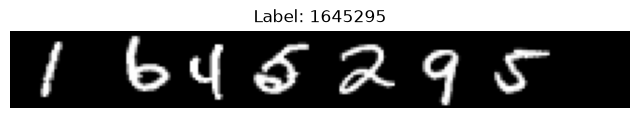

In [7]:
plt.figure(figsize=(8, 2))
plt.imshow(X_train[2].squeeze(), cmap='gray')
plt.title(f"Label: {y_train[2]}")
plt.axis('off')
plt.show()

## 3. Xây dựng mô hình

In [8]:
def build_model(img_shape, vocab_size, max_seq_len):
    # Encoder
    enc_inputs = Input(shape=img_shape, name='encoder_input')
    x = Conv2D(32, (3, 3), padding='same', use_bias=False)(enc_inputs)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = MaxPooling2D((2, 2))(x)

    x = Conv2D(64, (3, 3), padding='same', use_bias=False)(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = MaxPooling2D((2, 2))(x)                             # (7, 56, 64)

    x = Permute((2, 1, 3))(x)                               # (56, 7, 64)
    x = Reshape((56, 7 * 64))(x)                            # (56 timesteps, 448 features)
    enc_out, f_h, b_h = Bidirectional(GRU(64, return_sequences=True, return_state=True))(x)
    enc_state = Concatenate()([f_h, b_h])

    # Decoder
    dec_input = Input(shape=(max_seq_len,), name='decoder_input')
    dec_emb = Embedding(vocab_size, 128)(dec_input)
    dec_out = GRU(128, return_sequences=True)(dec_emb, initial_state=enc_state)

    # Attention mechanism
    context  = AdditiveAttention()([dec_out, enc_out])
    combined = Concatenate()([context, dec_out])

    # Output layer
    output = Dense(vocab_size, activation='softmax')(combined)

    return Model(inputs=[enc_inputs, dec_input], outputs=output)

In [9]:
model = build_model(IMG_SHAPE, VOCAB_SIZE, MAX_SEQ_LEN)
model.compile(optimizer=AdamW(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 28, 224,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 28, 224,   │        288 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 28, 224,   │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 28, 224,   │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 14, 112,   │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 14, 112,   │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 112,   │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 14, 112,   │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 7, 56, 64) │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, 56, 7, 64) │          0 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 56, 448)   │          0 │ permute[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, 9)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ [(None, 56, 128), │    197,376 │ reshape[0][0]     │
│ (Bidirectional)     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 9, 128)    │      1,664 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ bidirectional[0]… │
│ (Concatenate)       │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 9, 128)    │     99,072 │ embedding[0][0],  │
│                     │                   │            │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ additive_attention  │ (None, 9, 128)    │        128 │ gru_1[0][0],      │
│ (AdditiveAttention) │                   │            │ bidirectional[0]

 Total params: 320,685 (1.22 MB)

 Trainable params: 320,493 (1.22 MB)

 Non-trainable params: 192 (768.00 B)

## 4. Huấn luyện mô hình

In [10]:
early_stopping = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.2,
    patience=2,
    min_lr=1e-7
)

callbacks = [early_stopping, reduce_lr]

In [11]:
history = model.fit(
    [X_train, train_in], train_out,
    validation_data=([X_val, val_in], val_out),
    batch_size=128,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
329/329 ━━━━━━━━━━━━━━━━━━━━ 110s 320ms/step - accuracy: 0.6732 - loss: 0.9811 - val_accuracy: 0.3813 - val_loss: 9.0516 - learning_rate: 0.0010
Epoch 2/20
329/329 ━━━━━━━━━━━━━━━━━━━━ 106s 322ms/step - accuracy: 0.9574 - loss: 0.1726 - val_accuracy: 0.9745 - val_loss: 0.1010 - learning_rate: 0.0010
Epoch 3/20
329/329 ━━━━━━━━━━━━━━━━━━━━ 108s 329ms/step - accuracy: 0.9877 - loss: 0.0513 - val_accuracy: 0.9844 - val_loss: 0.0540 - learning_rate: 0.0010
Epoch 4/20
329/329 ━━━━━━━━━━━━━━━━━━━━ 110s 335ms/step - accuracy: 0.9931 - loss: 0.0279 - val_accuracy: 0.9926 - val_loss: 0.0260 - learning_rate: 0.0010
Epoch 5/20
329/329 ━━━━━━━━━━━━━━━━━━━━ 111s 337ms/step - accuracy: 0.9870 - loss: 0.0473 - val_accuracy: 0.9315 - val_loss: 0.2035 - learning_rate: 0.0010
Epoch 6/20
329/329 ━━━━━━━━━━━━━━━━━━━━ 111s 336ms/step - accuracy: 0.9950 - loss: 0.0205 - val_accuracy: 0.9942 - val_loss: 0.0214 - learning_rate: 0.0010
Epoch 7/20
329/329 ━━━━━━━━━━━━━━━━━━━━ 111s 338ms/step - accura

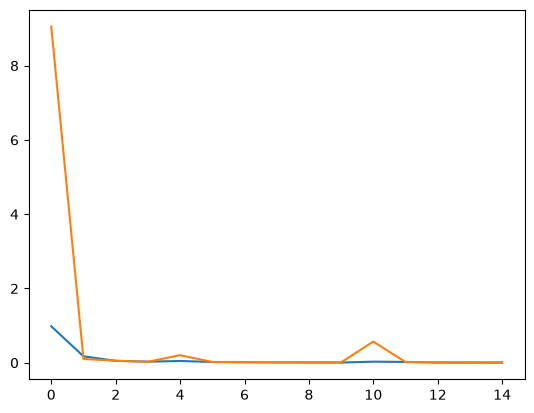

In [12]:
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')

## 4. Đánh giá trên tập Test

In [13]:
def predict_sequences(model, images, max_seq_len=MAX_SEQ_LEN, start_token=START_TOKEN, pad_token=PAD_TOKEN):
    n_samples = images.shape[0]
    input_seq = np.full((n_samples, max_seq_len + 1), pad_token, dtype=np.int32)
    input_seq[:, 0] = start_token

    for i in range(max_seq_len):
        preds = model.predict([images, input_seq[:, :max_seq_len]], batch_size=256, verbose=0)
        next_token = np.argmax(preds[:, i], axis=-1)
        input_seq[:, i + 1] = next_token

    outputs = []
    for seq in input_seq[:, 1:]:
        output = []
        for token in seq:
            if token >= 10: 
                break
            output.append(str(token))
        outputs.append(float(''.join(output)) if output else 0.0)

    return np.array(outputs, dtype=np.float64)

In [ ]:
def evaluate_model(y_true, y_pred, model_name="Model"):
    y_true_num = np.asarray(y_true, dtype=np.float64)
    y_pred_num = np.asarray(y_pred, dtype=np.float64)

    mae     = mean_absolute_error(y_true_num, y_pred_num)
    rmse    = np.sqrt(mean_squared_error(y_true_num, y_pred_num))
    r2      = r2_score(y_true_num, y_pred_num)
    denom   = np.sum((y_true_num - np.mean(y_true_num)) ** 2)
    nse     = 1.0 - np.sum((y_true_num - y_pred_num) ** 2) / denom if denom else np.nan
    acc     = accuracy_score(y_true_num, y_pred_num)

    print(f"=== {model_name} ===")
    print(f"R2: {r2:.4f} | NSE: {nse:.4f} | MAE: {mae:.4f} | RMSE: {rmse:.4f} | Accuracy: {acc:.4f}")
    return {"model": model_name, "R2": r2, "NSE": nse, "MAE": mae, "RMSE": rmse, "Accuracy": acc}

In [15]:
y_pred = predict_sequences(model, X_test)
results = evaluate_model(y_test, y_pred, model_name=f"Dai Model {VERSION}")

=== Dai Model v3 ===
R2: 0.9982 | NSE: 0.9982 | MAE: 29485.7660 | RMSE: 814850.6331 | Accuracy: 0.9711


In [16]:
import os

output_path = '../output/DaiModel/'
os.makedirs(output_path, exist_ok=True)

# Lưu mô hình (.keras là chuẩn mới của Keras 3)
model.save(output_path + f'dai_model_{VERSION}.keras')

# Đọc và ghi thêm kết quả vào CSV
csv_path = output_path + 'dai_model_results.csv'
results_df = pd.DataFrame([results])
if os.path.exists(csv_path):
    results_df = pd.concat([pd.read_csv(csv_path), results_df], ignore_index=True)
results_df.to_csv(csv_path, index=False)